# Spotify Tracks Dataset — Assignments 1 and 2

This notebook contains the assigned 2D regression/correlation work (A1) and PCA/SVD work (A2), with each task introduced by Markdown that states its purpose and method. Earlier exploratory analysis is retained as supplementary material.


## 1. Setup and imports

Run this first. Everything else depends on these imports.

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['figure.dpi'] = 110

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 170)

RANDOM_STATE = 42
DATA_PATH = 'spotify_dataset.csv'
CLEAN_OUTPUT_PATH = 'spotify_clean.csv'

print('pandas', pd.__version__, '| numpy', np.__version__, '| seaborn', sns.__version__)

pandas 3.0.6 | numpy 2.5.3 | seaborn 0.13.2


## 2. Load the dataset

The CSV sits in the same folder as this notebook, so a relative path is enough.

In [2]:
df_raw = pd.read_csv(DATA_PATH)

print('Rows    :', df_raw.shape[0])
print('Columns :', df_raw.shape[1])

Rows    : 114000
Columns : 21


In [3]:
df_raw.head()

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [4]:
for position, column in enumerate(df_raw.columns):
    print(position, repr(column))

0 'Unnamed: 0'
1 'track_id'
2 'artists'
3 'album_name'
4 'track_name'
5 'popularity'
6 'duration_ms'
7 'explicit'
8 'danceability'
9 'energy'
10 'key'
11 'loudness'
12 'mode'
13 'speechiness'
14 'acousticness'
15 'instrumentalness'
16 'liveness'
17 'valence'
18 'tempo'
19 'time_signature'
20 'track_genre'


## 3. Data types and summary statistics

`info()` shows the dtype of every column and how many non-null values it holds. `describe()` summarises the numeric columns.

In [5]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  str    
 2   artists           113999 non-null  str    
 3   album_name        113999 non-null  str    
 4   track_name        113999 non-null  str    
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          114000 non-nu

In [6]:
df_raw.dtypes.astype(str).value_counts().to_frame('columns')

,columns
float64,9
int64,6
str,5
bool,1


In [7]:
df_raw.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,114000.0,56999.500,32909.110,0.000,28499.750,56999.500,85499.250,113999.000
popularity,114000.0,33.239,22.305,0.000,17.000,35.000,50.000,100.000
duration_ms,114000.0,228029.153,107297.713,0.000,174066.000,212906.000,261506.000,5237295.000
danceability,114000.0,0.567,0.174,0.000,0.456,0.580,0.695,0.985
energy,114000.0,0.641,0.252,0.000,0.472,0.685,0.854,1.000
key,114000.0,5.309,3.560,0.000,2.000,5.000,8.000,11.000
loudness,114000.0,-8.259,5.029,-49.531,-10.013,-7.004,-5.003,4.532
mode,114000.0,0.638,0.481,0.000,0.000,1.000,1.000,1.000
speechiness,114000.0,0.085,0.106,0.000,0.036,0.049,0.084,0.965
acousticness,114000.0,0.315,0.333,0.000,0.017,0.169,0.598,0.996


In [8]:
text_columns = df_raw.select_dtypes(exclude='number').columns.tolist()

summary = pd.DataFrame({
    'unique_values': df_raw[text_columns].nunique(),
    'example': [df_raw[column].dropna().iloc[0] for column in text_columns],
})
summary

,unique_values,example
track_id,89741,5SuOikwiRyPMVoIQDJUgSV
artists,31437,Gen Hoshino
album_name,46589,Comedy
track_name,73608,Comedy
explicit,2,False
track_genre,114,acoustic


## 4. Data cleaning

Steps: drop the exported index column, handle missing values, remove duplicate tracks, fix impossible durations, and repair the categorical codes.

In [9]:
unnamed_columns = [
    column for column in df_raw.columns
    if str(column).strip() == '' or str(column).startswith('Unnamed')
]

df = df_raw.drop(columns=unnamed_columns).copy()
print('Dropped columns :', unnamed_columns)
print('New shape       :', df.shape)

Dropped columns : ['Unnamed: 0']
New shape       : (114000, 20)


In [10]:
missing_counts = df.isna().sum()
missing_counts[missing_counts > 0].to_frame('missing_values')

,missing_values
artists,1
album_name,1
track_name,1


In [11]:
df[df.isna().any(axis=1)]

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
65900,1kR4gIb7nGxHPI3D2ifs59,NaN,NaN,NaN,0,0,False,0.501,0.583,7,-9.46,0,0.0605,0.69,0.00396,0.0747,0.734,138.391,4,k-pop


In [12]:
print('Rows before :', df.shape[0])
df = df.dropna().reset_index(drop=True)
print('Rows after  :', df.shape[0])

Rows before : 114000
Rows after  : 113999


In [13]:
print('Fully duplicated rows        :', int(df.duplicated().sum()))
print('Rows repeating a track_id    :', int(df.duplicated(subset=['track_id']).sum()))

Fully duplicated rows        : 450
Rows repeating a track_id    : 24259


### 4.1 One row per track

The same `track_id` can appear under several genres (a track may be labelled both `acoustic` and `pop`). Track-level analysis wants exactly one row per track, so duplicates are removed by `track_id`.

In [14]:
tracks = df.drop_duplicates(subset=['track_id'], keep='first').reset_index(drop=True)

print('Rows in df    :', df.shape[0])
print('Unique tracks :', tracks.shape[0])

Rows in df    : 113999
Unique tracks : 89740


### 4.2 Duration

Milliseconds are hard to read, so a `duration_min` column is added. A handful of tracks are hours long (DJ mixes, white noise) and would distort averages.

In [15]:
tracks['duration_min'] = tracks['duration_ms'] / 60000
tracks['duration_min'].describe().round(2).to_frame('duration_min')

,duration_min
count,89740.00
mean,3.82
std,1.88
min,0.14
25%,2.88
50%,3.55
75%,4.40
max,87.29


In [16]:
MAX_TRACK_MINUTES = 15

long_tracks = tracks[tracks['duration_min'] > MAX_TRACK_MINUTES]
print('Tracks longer than', MAX_TRACK_MINUTES, 'minutes :', long_tracks.shape[0])
long_tracks[['track_name', 'artists', 'duration_min']].head(10)

Tracks longer than 15 minutes : 141


,track_name,artists,duration_min
4348,1/1 - Remastered 2004,Brian Eno,17.358667
5404,Fra dyden,ORM,24.643633
5455,"Floden, som kan skabe",ORM,24.263017
5504,Mod døden,ORM,23.850700
5557,"Trance/Floden, som kan lede",ORM,19.387500
5807,Winter,Nargaroth,16.711550
5856,Klippens Lyse Hal,ORM,23.255633
8466,Tu És o Centro (Ao Vivo),Frei Gilson,22.624183
8502,Seu Amor Me Persegue (Ao Vivo),Casa Worship;Julliany Souza,17.264917
8596,Abraça-me / Lindo És / Só Quero Ver Você,David Quinlan,15.774567


In [17]:
tracks = tracks[tracks['duration_min'] <= MAX_TRACK_MINUTES].reset_index(drop=True)
print('Rows after removing very long tracks :', tracks.shape[0])

Rows after removing very long tracks : 89599


### 4.3 Categorical codes

`key` (0-11) and `mode` (0/1) are numeric codes, and `time_signature` contains impossible values (0 and 1 beats per bar). Decoding the codes makes the plots readable.

In [18]:
tracks['time_signature'].value_counts().sort_index().to_frame('tracks')

,tracks
time_signature,
0,160
1,844
3,7582
4,79429
5,1584


In [19]:
VALID_TIME_SIGNATURES = [3, 4, 5]

invalid_mask = ~tracks['time_signature'].isin(VALID_TIME_SIGNATURES)
print('Rows with an unusual time_signature :', int(invalid_mask.sum()))

tracks = tracks[~invalid_mask].reset_index(drop=True)
print('Rows remaining :', tracks.shape[0])

Rows with an unusual time_signature : 1004
Rows remaining : 88595


In [20]:
KEY_NAMES = {0: 'C', 1: 'C#', 2: 'D', 3: 'D#', 4: 'E', 5: 'F',
             6: 'F#', 7: 'G', 8: 'G#', 9: 'A', 10: 'A#', 11: 'B'}
MODE_NAMES = {0: 'minor', 1: 'major'}

tracks['key_name'] = tracks['key'].map(KEY_NAMES)
tracks['mode_name'] = tracks['mode'].map(MODE_NAMES)
tracks['explicit'] = tracks['explicit'].astype(str).str.strip().str.lower() == 'true'

tracks[['track_name', 'key', 'key_name', 'mode', 'mode_name', 'explicit']].head()

,track_name,key,key_name,mode,mode_name,explicit
0,Comedy,1,C#,0,minor,False
1,Ghost - Acoustic,1,C#,1,major,False
2,To Begin Again,0,C,1,major,False
3,Can't Help Falling In Love,0,C,1,major,False
4,Hold On,2,D,1,major,False


In [21]:
print('Cleaned shape :', tracks.shape)
print('Explicit flag types :', tracks['explicit'].dtype)
tracks['explicit'].value_counts().to_frame('tracks')

Cleaned shape : (88595, 23)
Explicit flag types : bool


,tracks
explicit,
False,80970
True,7625


In [22]:
CLEAN_NUMERIC_COLUMNS = tracks.select_dtypes(include='number').columns.tolist()
tracks[CLEAN_NUMERIC_COLUMNS].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
popularity,88595.0,33.254,20.603,0.000,19.000,33.000,49.000,100.000
duration_ms,88595.0,227298.935,88084.239,15800.000,173450.000,213476.000,264160.000,896445.000
danceability,88595.0,0.565,0.174,0.051,0.453,0.578,0.693,0.985
energy,88595.0,0.637,0.254,0.000,0.462,0.679,0.854,1.000
key,88595.0,5.287,3.561,0.000,2.000,5.000,8.000,11.000
loudness,88595.0,-8.424,5.122,-46.591,-10.245,-7.144,-5.092,4.532
mode,88595.0,0.637,0.481,0.000,0.000,1.000,1.000,1.000
speechiness,88595.0,0.087,0.112,0.022,0.036,0.049,0.086,0.965
acousticness,88595.0,0.325,0.337,0.000,0.017,0.184,0.618,0.996
instrumentalness,88595.0,0.171,0.322,0.000,0.000,0.000,0.088,1.000


## 5. Univariate analysis

One variable at a time: how is each column distributed, and are there obvious problems?

### 5.1 Target variable: `popularity`

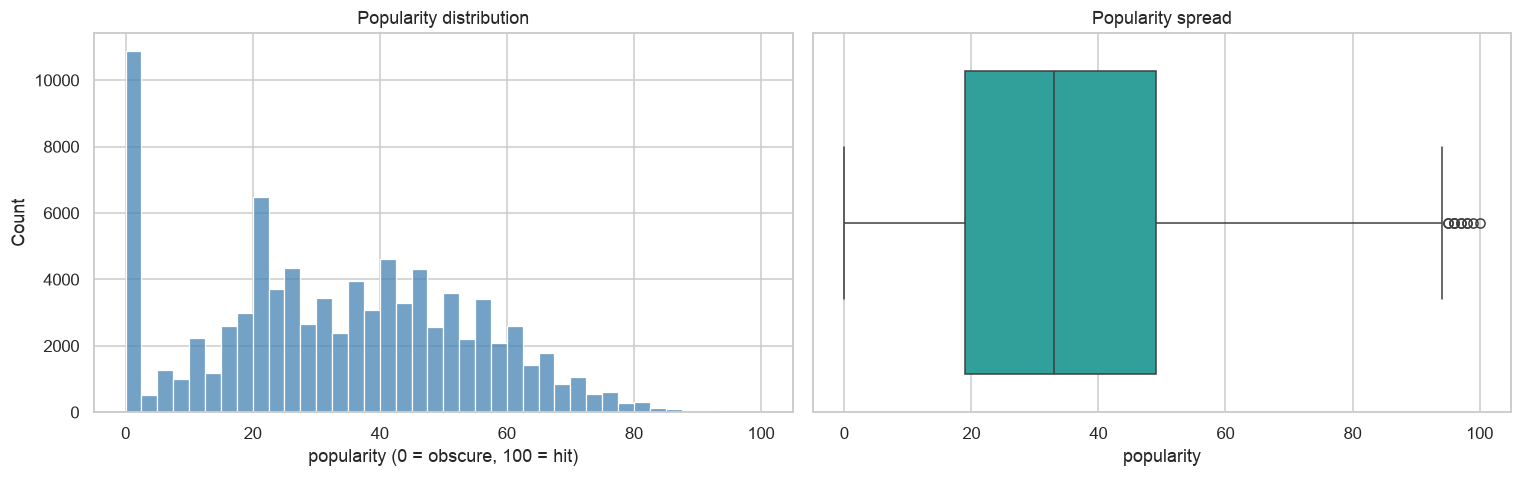

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.histplot(tracks['popularity'], bins=40, ax=axes[0], color='steelblue')
axes[0].set_title('Popularity distribution')
axes[0].set_xlabel('popularity (0 = obscure, 100 = hit)')

sns.boxplot(x=tracks['popularity'], ax=axes[1], color='lightseagreen')
axes[1].set_title('Popularity spread')

plt.tight_layout()
plt.show()

In [24]:
zero_share = 100 * (tracks['popularity'] == 0).mean()
print('Mean popularity         :', round(tracks['popularity'].mean(), 2))
print('Median popularity       :', tracks['popularity'].median())
print('Skewness                :', round(tracks['popularity'].skew(), 3))
print('Share with popularity 0 :', round(zero_share, 2), '%')

Mean popularity         : 33.25
Median popularity       : 33.0
Skewness                : 0.069
Share with popularity 0 : 10.51 %


### 5.2 Continuous audio features

Most audio features are already normalised to 0-1. `loudness` (dB) and `tempo` (BPM) are on their own scales.

In [25]:
AUDIO_FEATURES = [
    'danceability', 'energy', 'loudness', 'speechiness', 'acousticness',
    'instrumentalness', 'liveness', 'valence', 'tempo',
]

print(len(AUDIO_FEATURES), 'continuous audio features')
tracks[AUDIO_FEATURES].describe().T.round(3)

9 continuous audio features


,count,mean,std,min,25%,50%,75%,max
danceability,88595.0,0.565,0.174,0.051,0.453,0.578,0.693,0.985
energy,88595.0,0.637,0.254,0.000,0.462,0.679,0.854,1.000
loudness,88595.0,-8.424,5.122,-46.591,-10.245,-7.144,-5.092,4.532
speechiness,88595.0,0.087,0.112,0.022,0.036,0.049,0.086,0.965
acousticness,88595.0,0.325,0.337,0.000,0.017,0.184,0.618,0.996
instrumentalness,88595.0,0.171,0.322,0.000,0.000,0.000,0.088,1.000
liveness,88595.0,0.216,0.194,0.009,0.098,0.132,0.278,1.000
valence,88595.0,0.472,0.262,0.000,0.253,0.461,0.684,0.995
tempo,88595.0,122.415,29.683,30.200,99.830,122.061,140.130,243.372


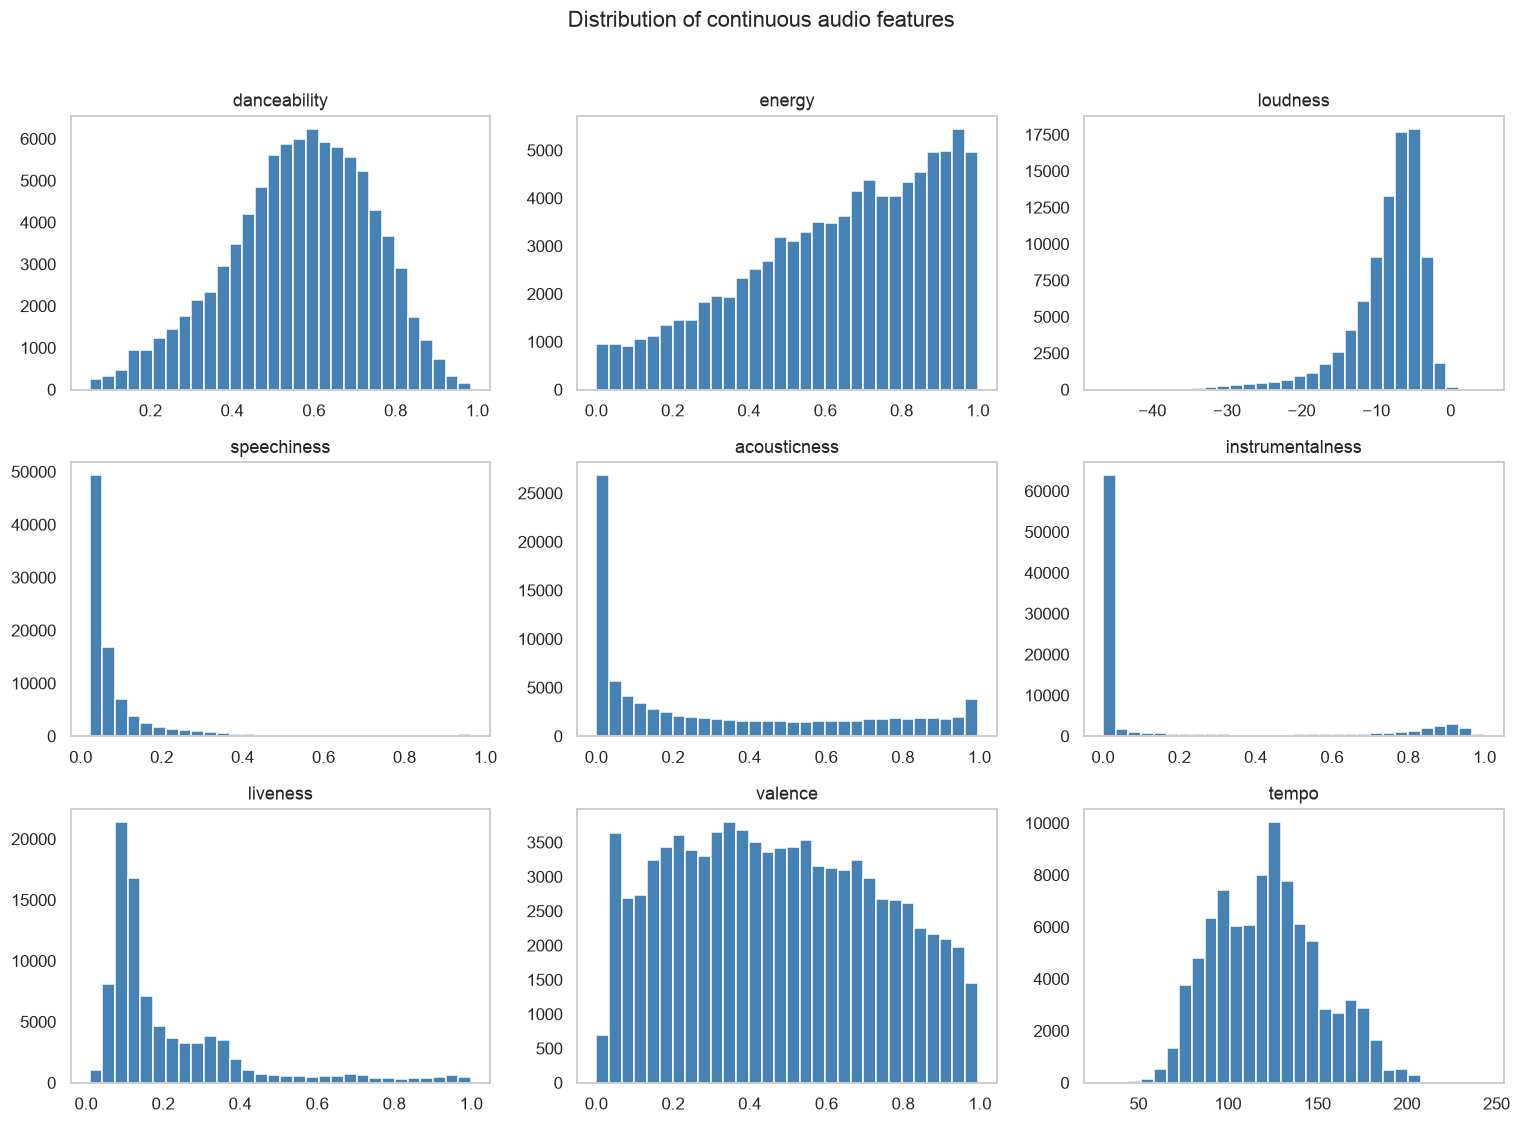

In [26]:
tracks[AUDIO_FEATURES].hist(
    figsize=(14, 10), bins=30, color='steelblue', edgecolor='white', grid=False
)
plt.suptitle('Distribution of continuous audio features', y=1.02)
plt.tight_layout()
plt.show()

### 5.3 Categorical columns

Counts for the explicit flag, the genres, and the musical key/mode.

not explicit    80970
explicit         7625
Name: tracks, dtype: int64


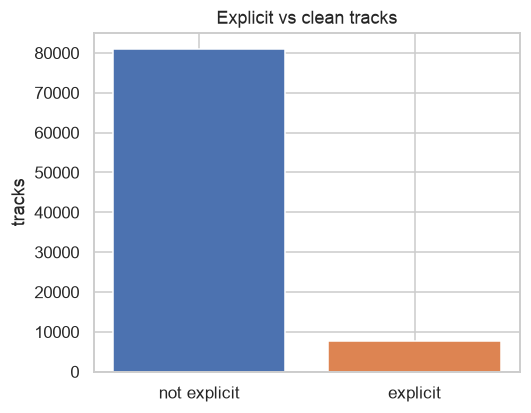

In [27]:
explicit_counts = tracks['explicit'].value_counts()
explicit_labels = ['explicit' if value else 'not explicit' for value in explicit_counts.index]

print(pd.Series(explicit_counts.values, index=explicit_labels, name='tracks'))

plt.figure(figsize=(5, 4))
plt.bar(explicit_labels, explicit_counts.values, color=['#4c72b0', '#dd8452'])
plt.title('Explicit vs clean tracks')
plt.ylabel('tracks')
plt.show()

Number of genres  : 113
Most common genre : cantopop with 998 tracks


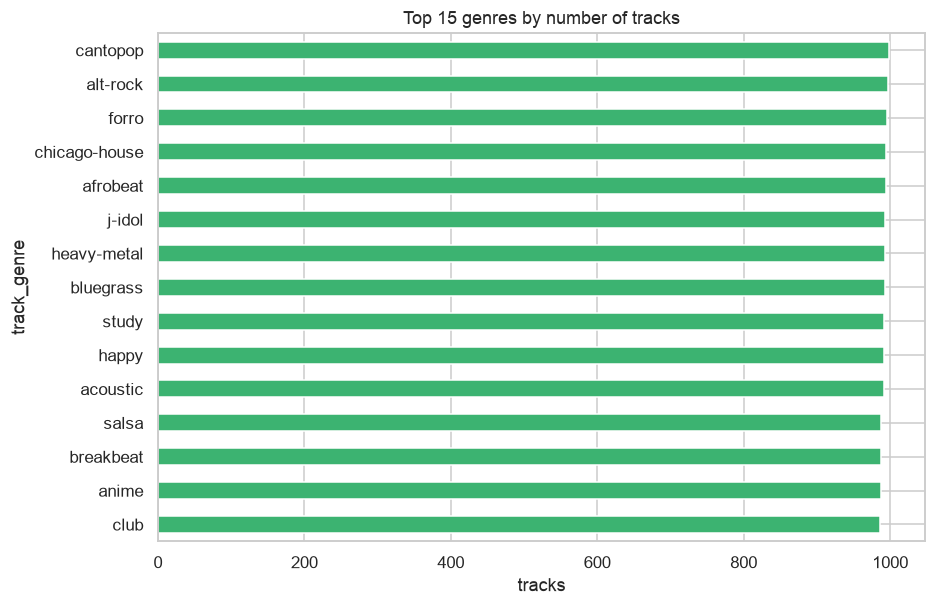

In [28]:
genre_counts = tracks['track_genre'].value_counts()
print('Number of genres  :', genre_counts.size)
print('Most common genre :', genre_counts.index[0], 'with', genre_counts.iloc[0], 'tracks')

genre_counts.head(15).sort_values().plot(kind='barh', figsize=(9, 6), color='mediumseagreen')
plt.title('Top 15 genres by number of tracks')
plt.xlabel('tracks')
plt.show()

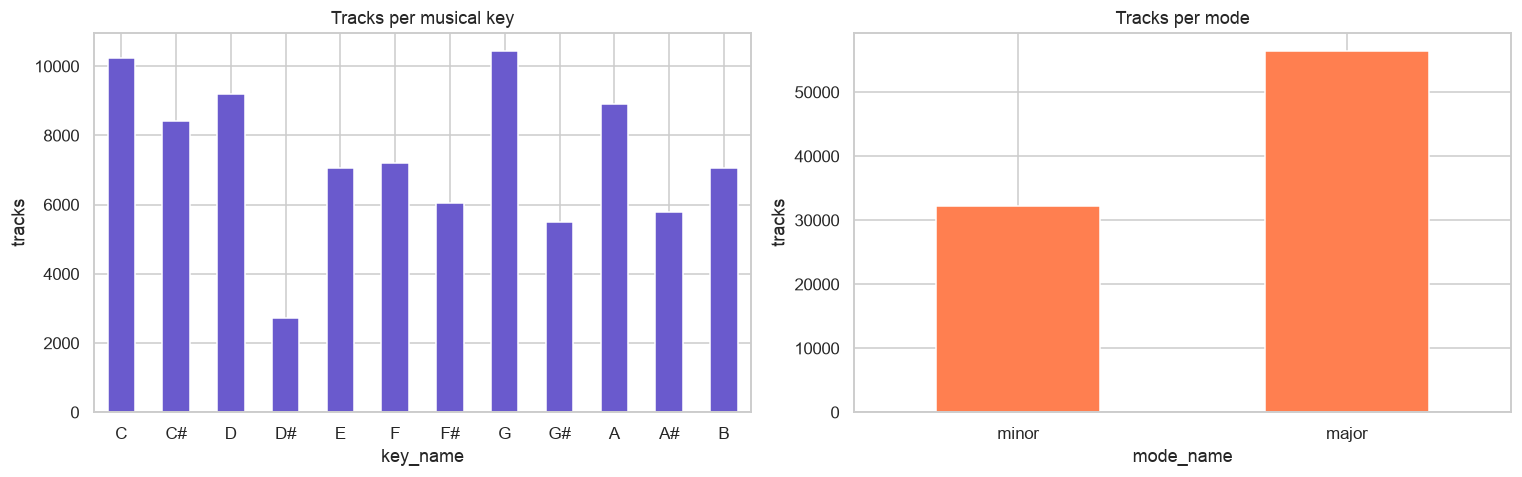

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

key_counts = tracks['key_name'].value_counts().reindex(list(KEY_NAMES.values())).fillna(0)
key_counts.plot(kind='bar', ax=axes[0], rot=0, color='slateblue')
axes[0].set_title('Tracks per musical key')
axes[0].set_ylabel('tracks')

mode_counts = tracks['mode_name'].value_counts().reindex(list(MODE_NAMES.values())).fillna(0)
mode_counts.plot(kind='bar', ax=axes[1], rot=0, color='coral')
axes[1].set_title('Tracks per mode')
axes[1].set_ylabel('tracks')

plt.tight_layout()
plt.show()

## 6. Bivariate analysis

How do features relate to each other and to popularity? Pearson correlation only captures straight-line relationships, but it is a useful first pass.

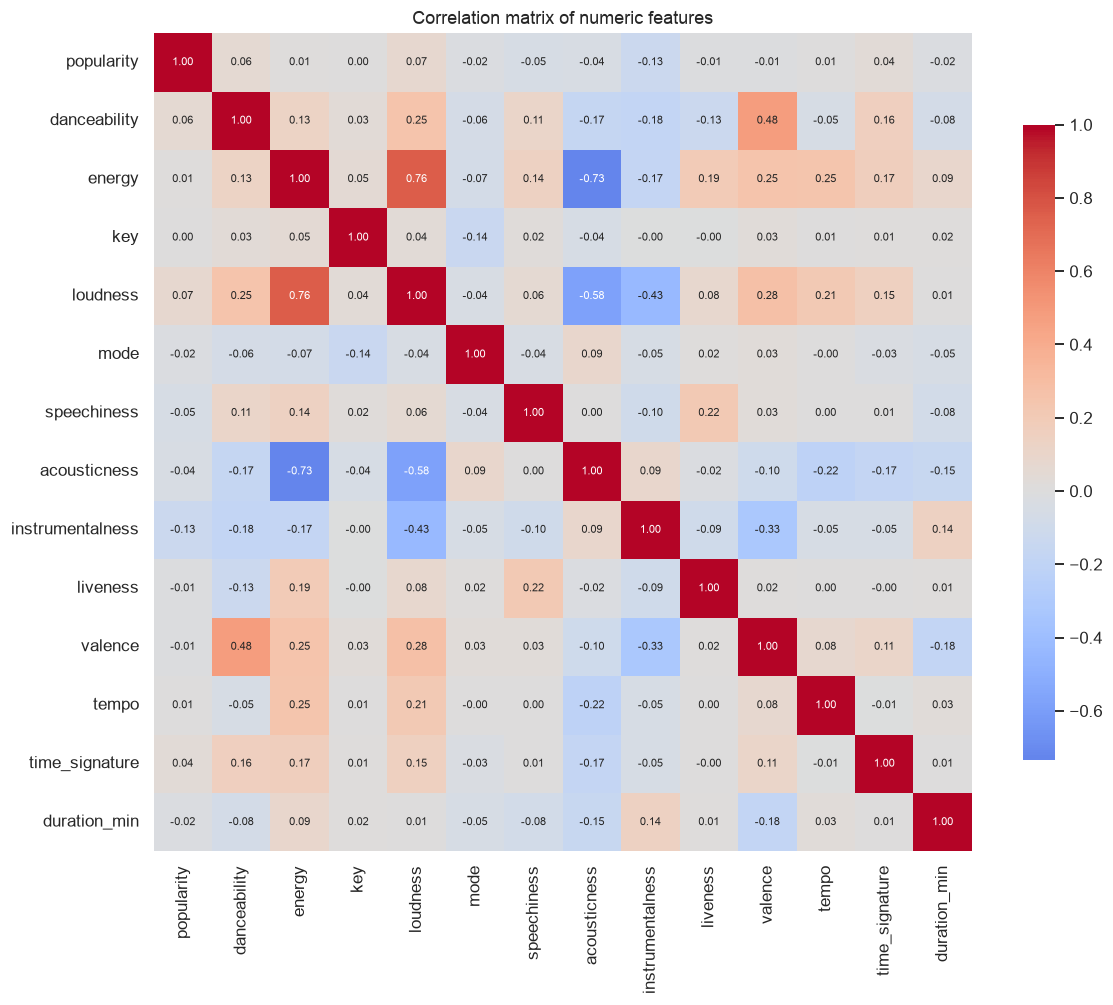

In [30]:
correlation_source = tracks.select_dtypes(include='number').drop(columns=['duration_ms'])
correlation = correlation_source.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(
    correlation, cmap='coolwarm', center=0, annot=True, fmt='.2f',
    annot_kws={'size': 7}, square=True, cbar_kws={'shrink': 0.75},
)
plt.title('Correlation matrix of numeric features')
plt.show()

                  corr_with_popularity
instrumentalness                -0.128
speechiness                     -0.046
acousticness                    -0.036
duration_min                    -0.020
mode                            -0.016
valence                         -0.013
liveness                        -0.013
key                              0.002
tempo                            0.007
energy                           0.012
time_signature                   0.036
danceability                     0.063
loudness                         0.072


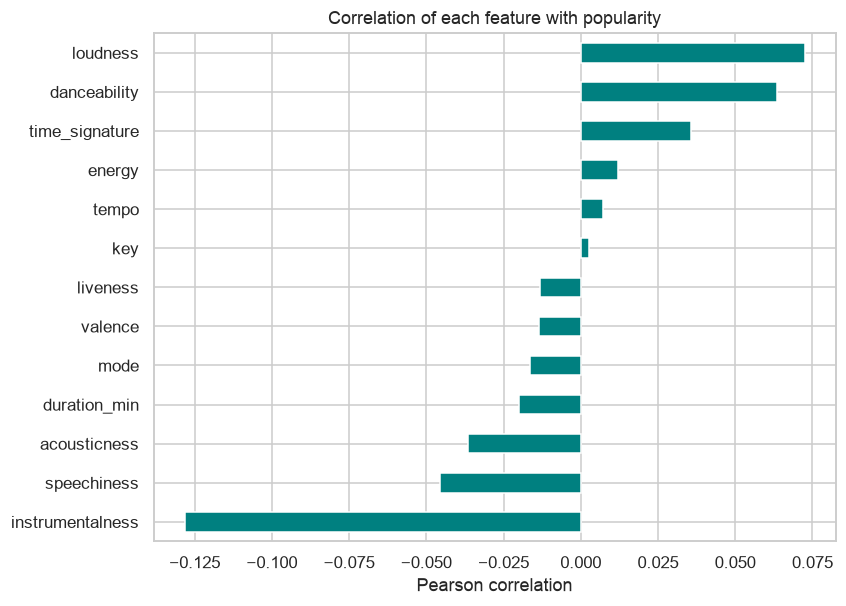

In [31]:
popularity_correlation = correlation['popularity'].drop('popularity').sort_values()

print(popularity_correlation.round(3).to_frame('corr_with_popularity'))

popularity_correlation.plot(kind='barh', figsize=(8, 6), color='teal')
plt.title('Correlation of each feature with popularity')
plt.xlabel('Pearson correlation')
plt.show()

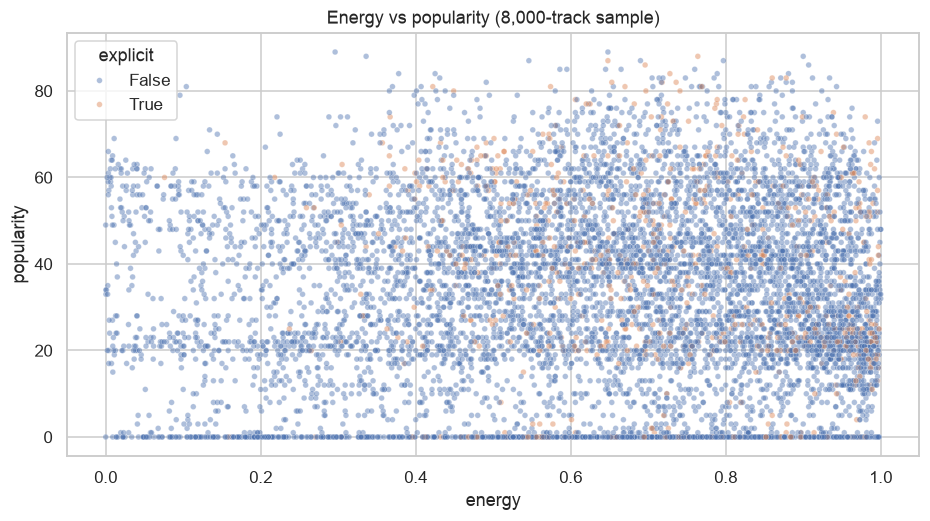

In [32]:
sample = tracks.sample(n=8000, random_state=RANDOM_STATE)

sns.scatterplot(data=sample, x='energy', y='popularity', hue='explicit', alpha=0.45, s=14)
plt.title('Energy vs popularity (8,000-track sample)')
plt.show()

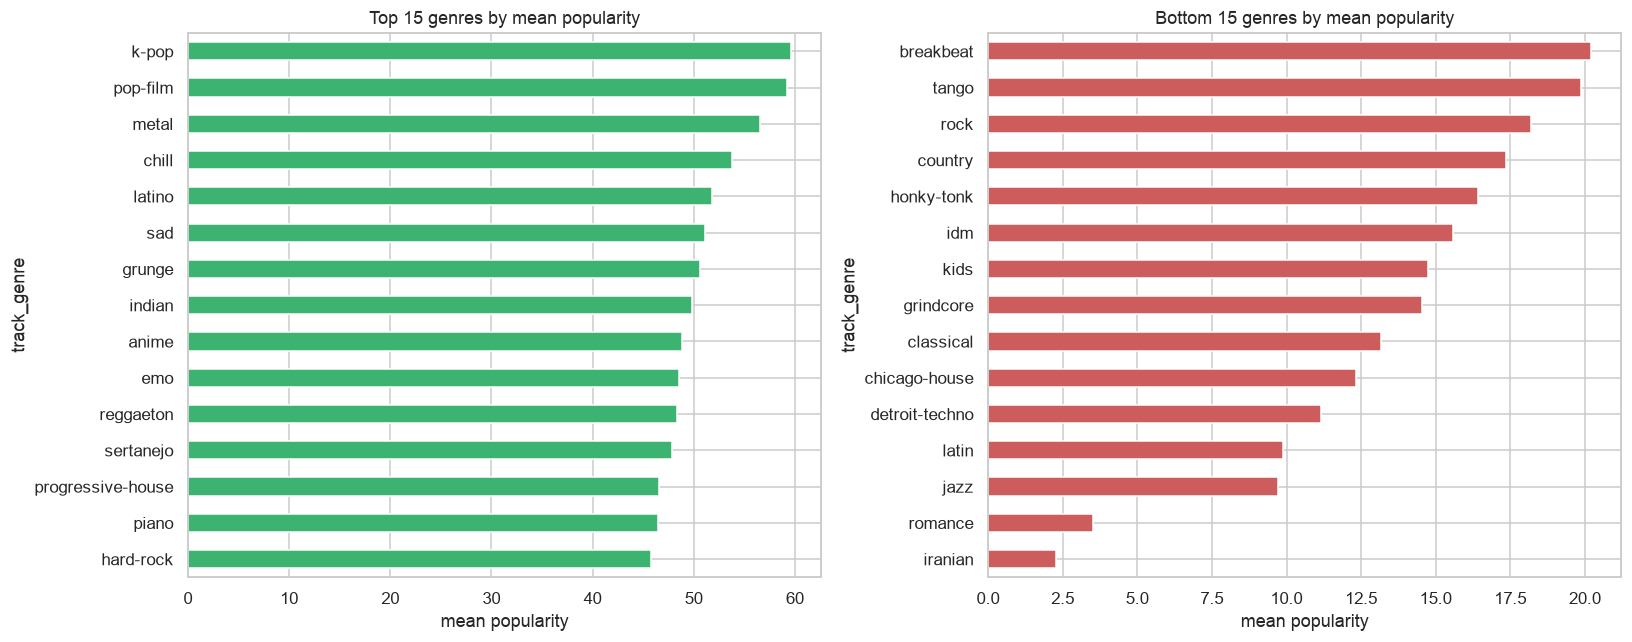

Most popular genres
             mean_popularity
track_genre                 
k-pop                  59.63
pop-film               59.18
metal                  56.52
chill                  53.76
latino                 51.82
Least popular genres
                mean_popularity
track_genre                    
detroit-techno            11.16
latin                      9.88
jazz                       9.71
romance                    3.53
iranian                    2.29


In [33]:
genre_popularity = tracks.groupby('track_genre')['popularity'].mean().sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
genre_popularity.head(15).sort_values().plot(kind='barh', ax=axes[0], color='mediumseagreen')
axes[0].set_title('Top 15 genres by mean popularity')
genre_popularity.tail(15).sort_values().plot(kind='barh', ax=axes[1], color='indianred')
axes[1].set_title('Bottom 15 genres by mean popularity')

for axis in axes:
    axis.set_xlabel('mean popularity')

plt.tight_layout()
plt.show()

print('Most popular genres')
print(genre_popularity.head(5).round(2).to_frame('mean_popularity'))
print('Least popular genres')
print(genre_popularity.tail(5).round(2).to_frame('mean_popularity'))

          count   mean  median
explicit                      
False     80970  32.90    33.0
True       7625  37.02    37.0


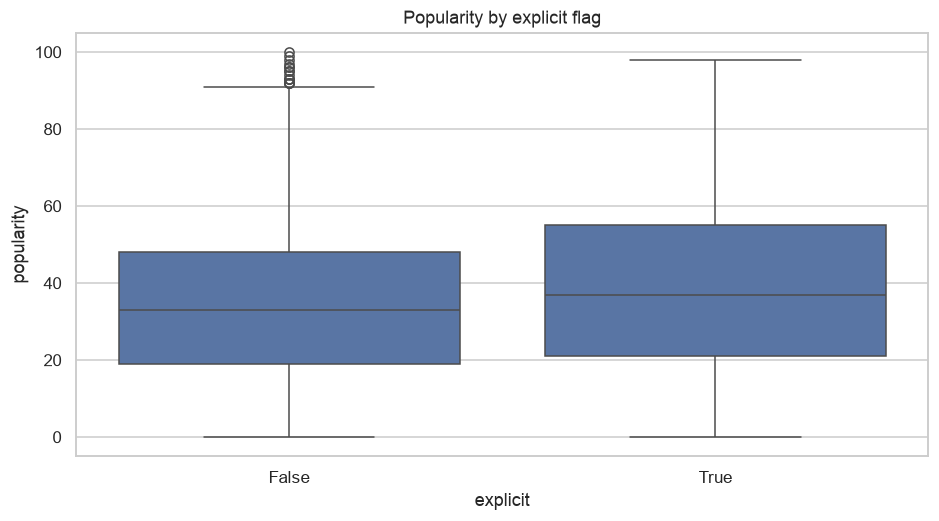

In [34]:
print(tracks.groupby('explicit')['popularity'].agg(['count', 'mean', 'median']).round(2))

sns.boxplot(data=tracks, x='explicit', y='popularity')
plt.title('Popularity by explicit flag')
plt.show()

## 7. Outlier detection with the IQR rule

The 1.5 x IQR rule marks values that sit far outside the middle 50% of a column. On strongly skewed features (`instrumentalness`, `speechiness`) this flags many perfectly valid tracks, so read the table as a warning list, not a delete list.

In [35]:
def iqr_outlier_bounds(series):
    """Return the lower and upper Tukey fences (1.5 x IQR) for a numeric series."""
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr


OUTLIER_COLUMNS = [
    'popularity', 'duration_min', 'danceability', 'energy', 'loudness',
    'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo',
]

outlier_rows = []
for column in OUTLIER_COLUMNS:
    lower, upper = iqr_outlier_bounds(tracks[column])
    flags = (tracks[column] < lower) | (tracks[column] > upper)
    outlier_rows.append({
        'feature': column,
        'lower_bound': round(lower, 3),
        'upper_bound': round(upper, 3),
        'outlier_count': int(flags.sum()),
        'outlier_pct': round(100 * flags.mean(), 2),
    })

outlier_report = pd.DataFrame(outlier_rows).sort_values('outlier_count', ascending=False)
outlier_report.reset_index(drop=True)

,feature,lower_bound,upper_bound,outlier_count,outlier_pct
0,instrumentalness,-0.132,0.220,19435,21.94
1,speechiness,-0.039,0.161,10477,11.83
2,liveness,-0.172,0.548,6835,7.71
3,loudness,-17.974,2.638,4807,5.43
4,duration_min,0.623,6.670,4091,4.62
5,danceability,0.093,1.053,384,0.43
6,tempo,39.381,200.579,377,0.43
7,popularity,-26.000,94.000,11,0.01
8,energy,-0.126,1.442,0,0.00
9,acousticness,-0.885,1.520,0,0.00


## 8. Machine learning 1: predicting the `explicit` flag

Binary classification: can the audio features separate explicit tracks from clean ones? Only about 9% of the tracks are explicit, so plain accuracy is misleading - the per-class scores in the classification report matter more.

In [36]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

print('scikit-learn is ready')

scikit-learn is ready


In [37]:
MODEL_FEATURES = [
    'danceability', 'energy', 'loudness', 'speechiness', 'acousticness',
    'instrumentalness', 'liveness', 'valence', 'tempo', 'duration_min',
]

X = tracks[MODEL_FEATURES]
y = tracks['explicit']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print('Train :', X_train.shape)
print('Test  :', X_test.shape)
print('Explicit share in train :', round(100 * y_train.mean(), 2), '%')

Train : (70876, 10)
Test  : (17719, 10)
Explicit share in train : 8.61 %


In [38]:
model = Pipeline(steps=[
    ('scaler', StandardScaler()),
    ('classifier', RandomForestClassifier(
        n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1,
    )),
])

model.fit(X_train, y_train)
predictions = model.predict(X_test)

print('Accuracy :', round(accuracy_score(y_test, predictions), 4))
print('Majority-class baseline :', round(max(y_test.mean(), 1 - y_test.mean()), 4))
print()
print(classification_report(y_test, predictions, target_names=['not explicit', 'explicit']))

Accuracy : 0.9258
Majority-class baseline : 0.9139

              precision    recall  f1-score   support

not explicit       0.93      0.99      0.96     16194
    explicit       0.72      0.23      0.35      1525

    accuracy                           0.93     17719
   macro avg       0.82      0.61      0.65     17719
weighted avg       0.91      0.93      0.91     17719



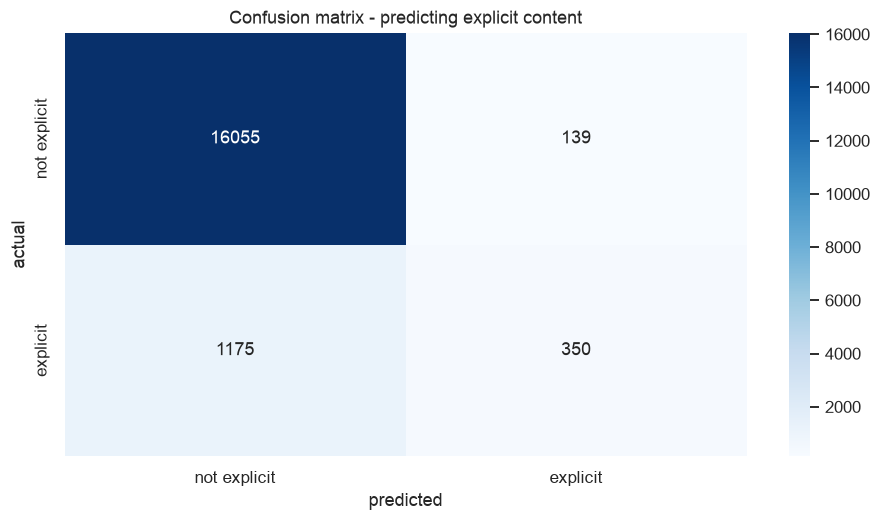

In [39]:
confusion = confusion_matrix(y_test, predictions)

sns.heatmap(
    confusion, annot=True, fmt='d', cmap='Blues',
    xticklabels=['not explicit', 'explicit'], yticklabels=['not explicit', 'explicit'],
)
plt.title('Confusion matrix - predicting explicit content')
plt.xlabel('predicted')
plt.ylabel('actual')
plt.show()

                  importance
speechiness           0.1784
danceability          0.1032
valence               0.0995
acousticness          0.0962
duration_min          0.0955
tempo                 0.0940
energy                0.0920
loudness              0.0911
liveness              0.0826
instrumentalness      0.0676


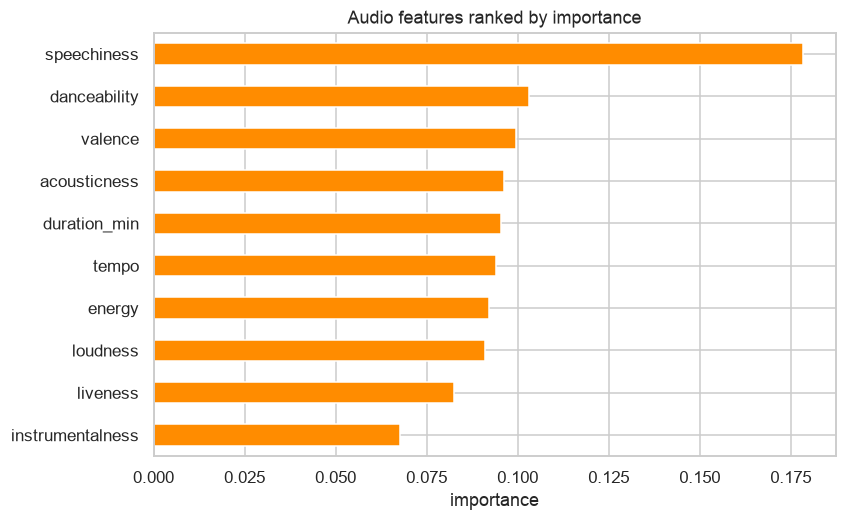

In [40]:
importances = pd.Series(
    model.named_steps['classifier'].feature_importances_, index=MODEL_FEATURES
).sort_values(ascending=False)

print(importances.round(4).to_frame('importance'))

importances.sort_values().plot(kind='barh', figsize=(8, 5), color='darkorange')
plt.title('Audio features ranked by importance')
plt.xlabel('importance')
plt.show()

## 9. Machine learning 2: clustering tracks with K-Means

Unsupervised learning: group tracks by their audio features without using the genre labels. The silhouette score measures how well separated the clusters are, so it is used to choose `k`.

In [41]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

CLUSTER_FEATURES = [
    'danceability', 'energy', 'acousticness', 'instrumentalness',
    'speechiness', 'valence', 'tempo',
]

cluster_matrix = StandardScaler().fit_transform(tracks[CLUSTER_FEATURES])
print('Feature matrix :', cluster_matrix.shape)

Feature matrix : (88595, 7)


In [42]:
silhouette_scores = {}
for k in range(2, 7):
    labels = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit_predict(cluster_matrix)
    silhouette_scores[k] = silhouette_score(
        cluster_matrix, labels, sample_size=10000, random_state=RANDOM_STATE
    )

silhouette_table = pd.Series(silhouette_scores, name='silhouette_score').to_frame()
silhouette_table.index.name = 'k'
silhouette_table.round(3)

,silhouette_score
k,
2,0.245
3,0.196
4,0.206
5,0.208
6,0.222


In [43]:
BEST_K = int(silhouette_table['silhouette_score'].idxmax())
kmeans = KMeans(n_clusters=BEST_K, random_state=RANDOM_STATE, n_init=10)
tracks['cluster'] = kmeans.fit_predict(cluster_matrix)

print('Best k by silhouette score :', BEST_K)
print('Silhouette score           :', round(silhouette_table.loc[BEST_K, 'silhouette_score'], 3))
print()
print(tracks['cluster'].value_counts().sort_index().to_frame('tracks'))

Best k by silhouette score : 2
Silhouette score           : 0.245

         tracks
cluster        
0         24864
1         63731


         danceability  energy  acousticness  instrumentalness  speechiness  valence    tempo  popularity  duration_min
cluster                                                                                                               
0               0.474   0.328         0.735             0.278        0.054    0.329  110.768      31.669         3.636
1               0.600   0.758         0.165             0.129        0.100    0.528  126.959      33.873         3.848


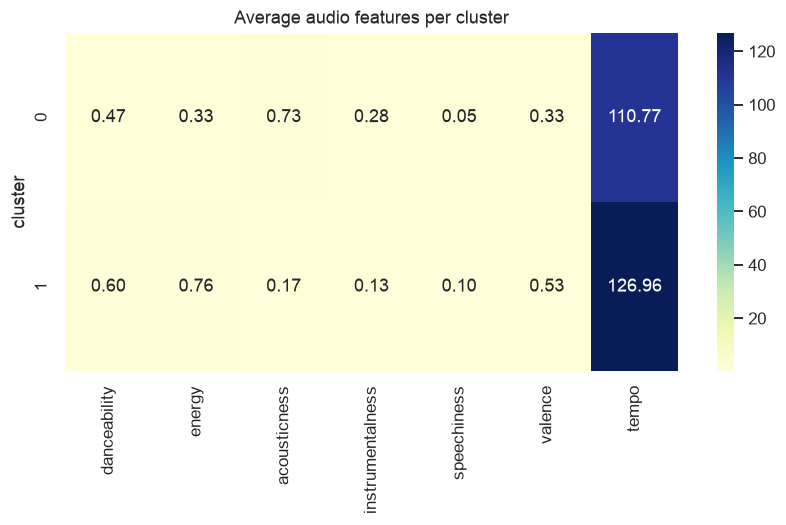

In [44]:
cluster_profile = (
    tracks.groupby('cluster')[CLUSTER_FEATURES + ['popularity', 'duration_min']]
    .mean()
    .round(3)
)
print(cluster_profile)

plt.figure(figsize=(9, 4))
sns.heatmap(cluster_profile[CLUSTER_FEATURES], annot=True, fmt='.2f', cmap='YlGnBu')
plt.title('Average audio features per cluster')
plt.show()

cluster          0    1
track_genre            
cantopop       645  353
alt-rock        98  899
forro           26  970
chicago-house    5  990
afrobeat       113  881
bluegrass      430  563
heavy-metal     19  974
j-idol          42  951
study          698  294
acoustic       618  373


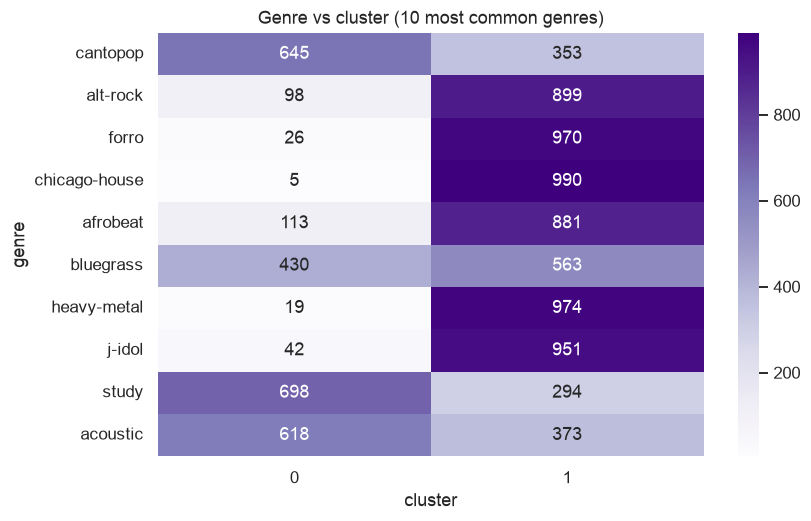

In [45]:
top_genres = tracks['track_genre'].value_counts().head(10).index
genre_cluster = pd.crosstab(tracks['track_genre'], tracks['cluster']).loc[top_genres]
print(genre_cluster)

plt.figure(figsize=(8, 5))
sns.heatmap(genre_cluster, annot=True, fmt='d', cmap='Purples')
plt.title('Genre vs cluster (10 most common genres)')
plt.xlabel('cluster')
plt.ylabel('genre')
plt.show()

## 10. Findings and next steps

**What the data shows**

- The raw file holds 114,000 rows across 114 genres. Cleaning drops the exported index, the single incomplete row, duplicate `track_id` values, 141 tracks longer than 15 minutes and 1,004 rows with an impossible time signature, leaving 88,595 unique tracks in 113 genres.
- `popularity` is nearly symmetric (mean 33.25, median 33.0, skewness 0.07) rather than skewed - but 10.5% of tracks sit at exactly 0, which is a large spike at the bottom and worth remembering before modelling.
- Every correlation with `popularity` is weak. The largest are instrumentalness (-0.13), then loudness (+0.07) and danceability (+0.06). Audio features alone clearly do not explain popularity.
- Explicit tracks are a small minority (7,625 of 88,595) and score slightly higher on average popularity (37.0 vs 32.9). The classifier leans almost entirely on `speechiness`, which has the highest importance by a wide margin (0.18 vs 0.10 for the runner-up).
- Genre averages differ enormously: k-pop (59.6), pop-film (59.2), metal (56.5) and chill (53.8) sit far above the dataset mean, while romance (3.5) and iranian (2.3) sit near the bottom. `metal` outranking `pop` is a good reminder that this column reflects the tracks sampled per genre, not worldwide listening.
- K-Means settles on two clusters, and they are readable: a quieter acoustic group (24,864 tracks, acousticness 0.74, energy 0.33) and a louder, more danceable group (63,731 tracks, energy 0.76, acousticness 0.17).

**Reasonable next steps**

1. Replace the single genre label with the full multi-genre list per track (the duplicate `track_id` rows are a lost opportunity for multi-label work).
2. Try regression instead of classification: predict `popularity` from the audio features and compare linear regression with gradient boosting.
3. Tune the classifier (class weights, gradient boosting, cross-validation) instead of a single train/test split.
4. Add text features from `track_name` and `album_name` (TF-IDF) alongside the audio features.

In [46]:
tracks.to_csv(CLEAN_OUTPUT_PATH, index=False)

print('Saved :', CLEAN_OUTPUT_PATH)
print('Rows  :', tracks.shape[0])
print('Columns :', tracks.shape[1])

Saved : spotify_clean.csv
Rows  : 88595
Columns : 24


# Assignment 1 — 2D regression and correlation

The assignment asks for a roughly linear feature pair, a scatterplot, an OLS line, correlation and determinacy, predictions, and an error comparison from the data-analysis (DA) and machine-learning (ML) perspectives. The report uses the same homogeneous `pop` subset and predictor/target throughout: energy predicts loudness.


## A1.1 Select and inspect the feature pair

**Why:** a scatterplot is the first check that a straight-line summary is reasonable. Using one genre reduces mixing differences between genres. `energy` is the predictor $x$ and `loudness` is the response $y$.


Complete pop observations: 1000
Repeated track IDs: 7


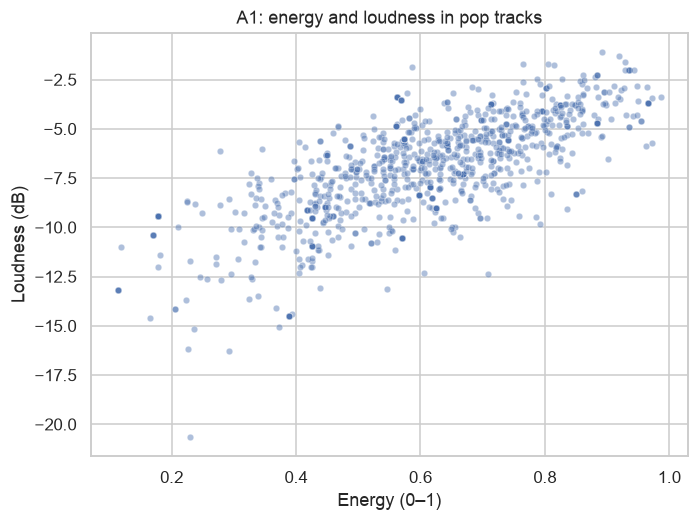

In [47]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

a1 = df_raw.loc[df_raw['track_genre'].eq('pop'), ['track_id', 'energy', 'loudness']].dropna().copy()
print('Complete pop observations:', len(a1))
print('Repeated track IDs:', int(a1['track_id'].duplicated().sum()))

plt.figure(figsize=(7, 5))
sns.scatterplot(data=a1, x='energy', y='loudness', alpha=0.45, s=18)
plt.title('A1: energy and loudness in pop tracks')
plt.xlabel('Energy (0–1)')
plt.ylabel('Loudness (dB)')
plt.show()


## A1.2 OLS, correlation, and determinacy

For points $(x_i,y_i)$, OLS minimizes $\sum_i(y_i-\hat y_i)^2$. The slope is $b_1=\sum_i(x_i-\bar x)(y_i-\bar y)/\sum_i(x_i-\bar x)^2$ and intercept $b_0=\bar y-b_1\bar x$. Pearson $r$ measures direction and strength of linear association; in simple OLS with an intercept, $R^2=r^2=1-SS_{res}/SS_{tot}$. $R^2$ is the fraction of sample variation in loudness accounted for by this fitted line, not a percent prediction accuracy.


In [48]:
x = a1[['energy']]
y = a1['loudness']
ols = LinearRegression().fit(x, y)
y_hat = ols.predict(x)
r = a1['energy'].corr(a1['loudness'])
ss_res = float(((y - y_hat) ** 2).sum())
ss_tot = float(((y - y.mean()) ** 2).sum())
print(f'b0={ols.intercept_:.6f}; b1={ols.coef_[0]:.6f}')
print(f'Fitted loudness = {ols.intercept_:.4f} + {ols.coef_[0]:.4f} * energy')
print(f'Pearson r={r:.6f}; R^2={r2_score(y, y_hat):.6f}; r^2={r*r:.6f}')
print(f'SS_res={ss_res:.3f}; SS_tot={ss_tot:.3f}; residual SD={np.sqrt(mean_squared_error(y, y_hat)):.3f} dB')


b0=-13.276484; b1=10.425675
Fitted loudness = -13.2765 + 10.4257 * energy
Pearson r=0.723035; R^2=0.522779; r^2=0.522779
SS_res=3130.777; SS_tot=6560.441; residual SD=1.769 dB


The slope is the fitted change in loudness, in dB, for a one-unit increase in energy; because energy spans 0–1, a 0.1 increase corresponds to $0.1b_1$ dB. This is an association, not a causal effect. The following residual plot checks whether systematic curvature remains.


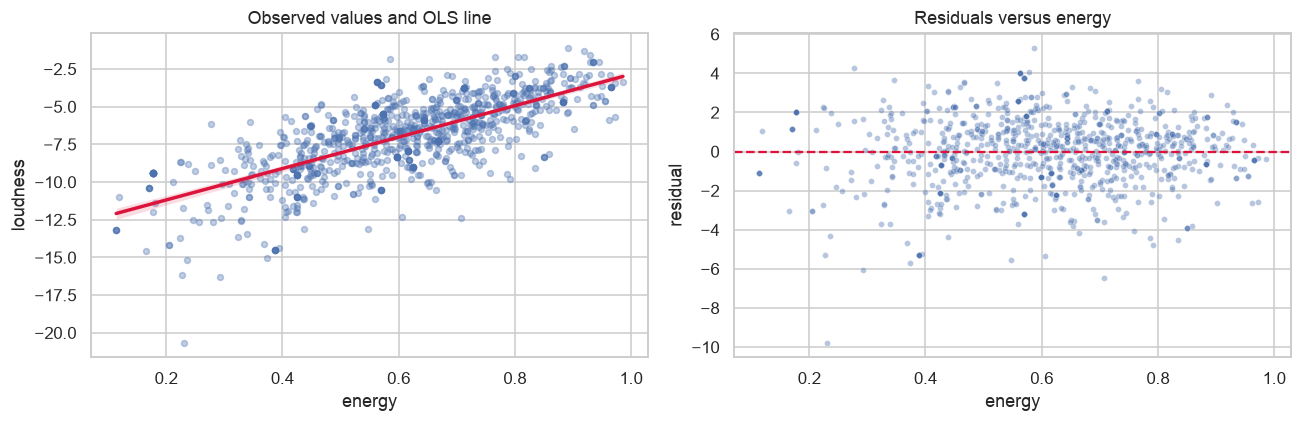

In [49]:
a1['fitted'] = y_hat
a1['residual'] = y - y_hat
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.regplot(data=a1, x='energy', y='loudness', scatter_kws={'alpha': .35, 's': 15}, line_kws={'color': 'crimson'}, ax=axes[0])
axes[0].set_title('Observed values and OLS line')
sns.scatterplot(data=a1, x='energy', y='residual', alpha=.4, s=15, ax=axes[1])
axes[1].axhline(0, color='crimson', linestyle='--')
axes[1].set_title('Residuals versus energy')
plt.tight_layout(); plt.show()


## A1.3 Predictions and relative absolute errors

For selected energy values, the prediction is $\hat y=b_0+b_1x$. We report the assignment’s two MRAE conventions explicitly: DA uses $|y_i|$ in the denominator and ML uses $|\hat y_i|$. A seeded 80/20 split evaluates generalization; the model is refitted using only training rows before test errors are calculated.


In [50]:
prediction_energy = pd.DataFrame({'energy': [0.2, 0.4, 0.6, 0.8]})
prediction_table = prediction_energy.assign(predicted_loudness=ols.predict(prediction_energy))
display(prediction_table.round(3))

def mrae_da(actual, predicted):
    return np.mean(np.abs(actual - predicted) / np.abs(actual))

def mrae_ml(actual, predicted):
    return np.mean(np.abs(actual - predicted) / np.abs(predicted))

print('Full-data MAE:', mean_absolute_error(y, y_hat))
print('Full-data MRAE DA / ML (%):', 100*mrae_da(y.to_numpy(), y_hat), 100*mrae_ml(y.to_numpy(), y_hat))
train_idx, test_idx = train_test_split(np.arange(len(a1)), test_size=.2, random_state=42)
ml_ols = LinearRegression().fit(x.iloc[train_idx], y.iloc[train_idx])
test_hat = ml_ols.predict(x.iloc[test_idx]); test_y = y.iloc[test_idx].to_numpy()
print('Train coefficients:', ml_ols.intercept_, ml_ols.coef_[0])
print('Test R^2:', r2_score(test_y, test_hat))
print('Test MAE:', mean_absolute_error(test_y, test_hat))
print('Test MRAE DA / ML (%):', 100*mrae_da(test_y, test_hat), 100*mrae_ml(test_y, test_hat))


,energy,predicted_loudness
0,0.2,-11.191
1,0.4,-9.106
2,0.6,-7.021
3,0.8,-4.936


Full-data MAE: 1.376079491378588
Full-data MRAE DA / ML (%): 23.128437877970644 20.44308393045321
Train coefficients: -13.329311180802575 10.521251826895874
Test R^2: 0.5101260650454618
Test MAE: 1.4375788927985644
Test MRAE DA / ML (%): 23.533193173981672 21.33770095221408


**Interpretation:** compare MAE/MRAE with $R^2$ rather than treating them as interchangeable. $R^2$ summarizes variation explained, while errors give typical prediction deviations on the target scale or relative to a chosen denominator. Relative errors are unstable near zero; here loudness is negative and the formulas use absolute denominators.

# Assignment 2 — PCA/SVD, visualization, and hidden ranking factor

The teacher’s lecture presents PCA as low-rank least-squares approximation: for preprocessed data matrix $X$, compute $X=U\Sigma V^T$. Component $k$ contributes $\sigma_k^2$ to total data scatter $\|X\|_F^2=\sum_k\sigma_k^2$; the percentage contribution is $100\sigma_k^2/\sum_j\sigma_j^2$. Singular-vector signs are arbitrary, so loading interpretations use relative signs and magnitudes.


## A2.1 Choose related features and pre-specify a group

We use four continuous audio features—energy, loudness, danceability, and valence—as interpretable descriptors of intensity/affective character. Loudness is measured in dB and the other three features are on 0–1 scales, so results depend on preprocessing. One row per `track_id` prevents genre duplicates from weighting the PCA repeatedly. Explicit tracks are the pre-specified group to mark in each visualization.


In [51]:
PCA_FEATURES = ['energy', 'loudness', 'danceability', 'valence']
pca_data = df_raw.drop_duplicates('track_id').dropna(subset=PCA_FEATURES + ['explicit']).copy()
X_original = pca_data[PCA_FEATURES].astype(float)
group_explicit = pca_data['explicit'].astype(str).str.strip().str.lower().eq('true').to_numpy()
print('Rows:', len(X_original), '| features:', PCA_FEATURES, '| explicit group:', int(group_explicit.sum()))


Rows: 89741 | features: ['energy', 'loudness', 'danceability', 'valence'] | explicit group: 7704


## A2.2 Model based PCA under range normalization and z-scoring

Range normalization maps each feature’s observed minimum and maximum to $-0.5$ and $+0.5$: $x'=(x-\min x)/(\max x-\min x)-0.5$. This preserves the lecture’s informative origin at the feature midrange. Z-scoring uses $z=(x-\bar x)/s_x$, putting every feature at mean zero and unit sample standard deviation. We calculate scatter and SVD separately for each transformation, then report each component’s natural contribution and percentage.


In [52]:
def pca_svd_summary(X):
    U, singular_values, Vt = np.linalg.svd(np.asarray(X), full_matrices=False)
    contributions = singular_values ** 2
    scatter = float(np.sum(np.asarray(X) ** 2))
    return U, singular_values, Vt, scatter, contributions, contributions / scatter

X_range = (X_original - X_original.min()) / (X_original.max() - X_original.min()) - 0.5
X_z = (X_original - X_original.mean()) / X_original.std(ddof=1)
pca_results = {}
for name, Xp in [('range', X_range), ('zscore', X_z)]:
    U, s, Vt, scatter, contrib, pct = pca_svd_summary(Xp)
    pca_results[name] = (U, s, Vt, Xp)
    print(f'\n{name}: scatter={scatter:.3f}')
    display(pd.DataFrame({'singular_value': s, 'contribution_sigma_squared': contrib, 'contribution_percent': 100*pct}, index=[f'PC{i+1}' for i in range(len(s))]).round(4))



range: scatter=24057.889


,singular_value,contribution_sigma_squared,contribution_percent
PC1,113.8398,12959.4899,53.8679
PC2,82.2603,6766.7507,28.1270
PC3,54.2991,2948.3876,12.2554
PC4,37.1922,1383.2610,5.7497



zscore: scatter=358960.000


,singular_value,contribution_sigma_squared,contribution_percent
PC1,436.9116,190891.7485,53.1791
PC2,319.0760,101809.4734,28.3623
PC3,214.0584,45821.0022,12.7649
PC4,142.9607,20437.7759,5.6936


## A2.3 Visualize the first two model based components

The first two score columns are $U[:,1:2]\Sigma[1:2,1:2]$. Each plot marks explicit tracks with a distinct color. The displayed two-dimensional contribution is the sum of the first two singular-value contributions divided by total scatter; it quantifies how much of the transformed data scatter these coordinates retain. Component signs can flip without changing the PCA solution.


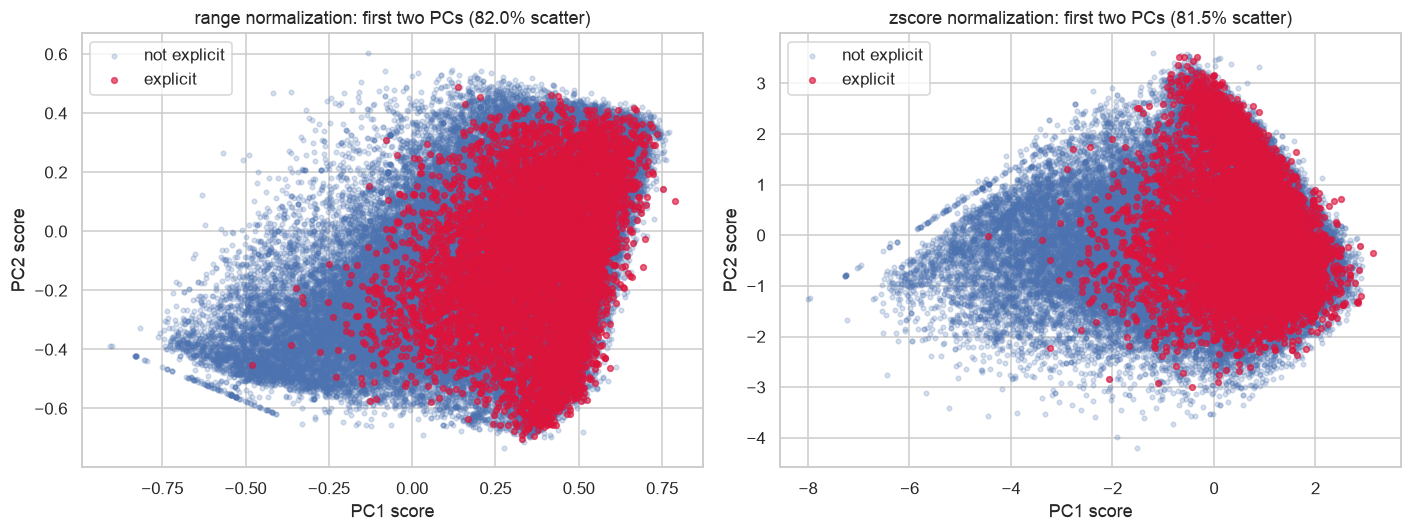

range explicit mean PC scores: [ 0.37 -0.1 ] | other mean PC scores: [ 0.262 -0.098]
zscore explicit mean PC scores: [0.539 0.058] | other mean PC scores: [-0.051 -0.005]


In [53]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, name in zip(axes, ['range', 'zscore']):
    U, s, Vt, Xp = pca_results[name]
    scores = U[:, :2] * s[:2]
    scatter_pct = 100 * np.sum(s[:2]**2) / np.sum(Xp.to_numpy()**2)
    ax.scatter(scores[~group_explicit, 0], scores[~group_explicit, 1], s=9, alpha=.22, label='not explicit')
    ax.scatter(scores[group_explicit, 0], scores[group_explicit, 1], s=14, alpha=.65, color='crimson', label='explicit')
    ax.set_title(f'{name} normalization: first two PCs ({scatter_pct:.1f}% scatter)')
    ax.set_xlabel('PC1 score'); ax.set_ylabel('PC2 score'); ax.legend()
plt.tight_layout(); plt.show()
for name in ['range', 'zscore']:
    U, s, Vt, Xp = pca_results[name]
    scores = U[:, :2] * s[:2]
    print(name, 'explicit mean PC scores:', scores[group_explicit].mean(axis=0).round(3),
          '| other mean PC scores:', scores[~group_explicit].mean(axis=0).round(3))


Loadings are columns of $V$ and describe how each feature contributes to each component. Large absolute loadings matter most; the sign indicates whether a feature moves with or against the component, subject to the arbitrary whole-component sign.


In [54]:
for name in ['range', 'zscore']:
    Vt = pca_results[name][2]
    print(name, 'loadings:')
    display(pd.DataFrame(Vt[:2].T, index=PCA_FEATURES, columns=['PC1', 'PC2']).round(4))


range loadings:


,PC1,PC2
energy,0.6867,-0.1159
loudness,0.6369,-0.2953
danceability,0.2816,0.2794
valence,0.2086,0.9063


zscore loadings:


,PC1,PC2
energy,0.5445,0.4789
loudness,0.5799,0.3731
danceability,0.4060,-0.6079
valence,0.4500,-0.5118


## A2.4 Conventional PCA and comparison

The conventional route diagonalizes the feature correlation matrix $B=Y^TY/(n-1)$, where $Y$ is the z-scored matrix. Eigenvectors are loadings; the score vector corresponding to unit-length eigenvector $c_k$ is $Yc_k$. This should match the z-scored model based SVD loadings and scores up to signs and scaling conventions.


In [55]:
B = X_z.to_numpy().T @ X_z.to_numpy() / (len(X_z) - 1)
eigenvalues, eigenvectors = np.linalg.eigh(B)
order = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[order]; eigenvectors = eigenvectors[:, order]
conventional_scores = X_z.to_numpy() @ eigenvectors[:, :2]
print('Correlation-matrix eigenvalues:', eigenvalues.round(6))
print('Variance shares (%):', (100*eigenvalues/eigenvalues.sum()).round(3))
print('Absolute loading agreement with SVD:')
print(np.abs(eigenvectors[:, :2].T @ pca_results['zscore'][2][:2].T).round(6))


Correlation-matrix eigenvalues: [2.127165 1.134494 0.510597 0.227744]
Variance shares (%): [53.179 28.362 12.765  5.694]
Absolute loading agreement with SVD:
[[1. 0.]
 [0. 1.]]


**Normalization comment:** compare the plots, loading patterns, and two-component scatter shares. Range normalization gives equal weight to observed spans; z-scoring gives equal weight in standard-deviation units and corresponds to conventional correlation-matrix PCA. The better choice depends on whether range or variance should define feature importance; for these differently scaled features, z-scoring is the more interpretable balanced comparison.

## A2.5 Hidden ranking factor on a 0–100 scale

Convert each feature to its percentile rank on 0–100, then obtain the first SVD loading vector of this ranking matrix. Orient its sign so its weights sum positively. Normalize weights to sum to one and calculate the weighted score. Finally rescale scores so the maximum observed score is 100. This follows the lecture’s loading-weighted hidden factor idea and explicitly states the calibration anchor; all values are relative to this sample.


In [56]:
from scipy.stats import rankdata
rank_matrix = np.column_stack([100 * (rankdata(X_original[c], method='average') - 1) / (len(X_original)-1) for c in PCA_FEATURES])
Ur, sr, Vtr = np.linalg.svd(rank_matrix, full_matrices=False)
weights = Vtr[0].copy()
if weights.sum() < 0:
    weights = -weights
weights = weights / weights.sum()
raw_factor = rank_matrix @ weights
ranking_factor_0_100 = 100 * raw_factor / raw_factor.max()
print('Normalized PC1 feature weights:')
display(pd.Series(weights, index=PCA_FEATURES, name='weight').to_frame().round(4))
print('0-100 factor summary:')
display(pd.Series(ranking_factor_0_100, name='factor').describe(percentiles=[.25,.5,.75]).round(2).to_frame())
pca_data['hidden_ranking_factor'] = ranking_factor_0_100
print('Explicit group mean factor:', round(pca_data.loc[group_explicit, 'hidden_ranking_factor'].mean(), 2))
print('Other tracks mean factor:', round(pca_data.loc[~group_explicit, 'hidden_ranking_factor'].mean(), 2))


Normalized PC1 feature weights:


,weight
energy,0.2520
loudness,0.2535
danceability,0.2447
valence,0.2498


0-100 factor summary:


,factor
count,89741.00
mean,51.42
std,20.56
min,0.06
25%,37.97
50%,53.74
75%,66.66
max,100.00


Explicit group mean factor: 59.12
Other tracks mean factor: 50.69


**Interpretation:** the factor is a data-derived summary of the four feature ranks, not a validated measure of musical quality. Read the weights and group means together; the 0–100 scale is anchored so the strongest observed composite equals 100, while typical sample scores can be much lower.
